In [1]:
import torch
import torch.nn as nn

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cpu


In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(
    root="../data/images",
    transform=transform
)

In [4]:
class_names = dataset.classes

In [5]:
train_size = int(0.7 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

In [6]:
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [ ]:
# Load EfficientNet-B0 architecture with default pre-trained weights
weights = models.EfficientNet_B0_Weights.DEFAULT
model = models.efficientnet_b0(weights=weights)

# Replace the final classification layer
num_classes = len(dataset.classes)

# In EfficientNet, the classifier is located inside a 'classifier' sequential container.
# The final layer is a Linear layer at index 1 inside this container.
in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    num_classes
)

# Load your trained weights
model.load_state_dict(
    torch.load("../models/efficientnet_b0_best.pth", map_location=device)
)

model = model.to(device)
model.eval()

# Image transforms optimized for EfficientNet-B0 input specifications
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("EfficientNet-B0 model loaded successfully!")

EfficientNet-B0 model loaded successfully!


In [8]:
all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

print("Testing complete!")

Testing complete!


In [9]:
accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Accuracy: {accuracy*100:.2f}%")

Test Accuracy: 86.22%


In [10]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
))

                            precision    recall  f1-score   support

              aerosol_cans       0.89      0.92      0.91        79
        aluminum_food_cans       0.60      0.46      0.52        80
        aluminum_soda_cans       0.78      0.91      0.84        80
           cardboard_boxes       0.52      0.72      0.60        72
       cardboard_packaging       0.62      0.42      0.50        80
                  clothing       0.87      0.94      0.91        72
            coffee_grounds       0.96      1.00      0.98        76
disposable_plastic_cutlery       0.98      0.97      0.98        67
                 eggshells       0.94      0.94      0.94        68
                food_waste       0.98      1.00      0.99        60
    glass_beverage_bottles       0.95      0.90      0.93        91
 glass_cosmetic_containers       0.93      0.97      0.95        65
           glass_food_jars       0.88      0.89      0.88        55
                 magazines       0.88      0.96

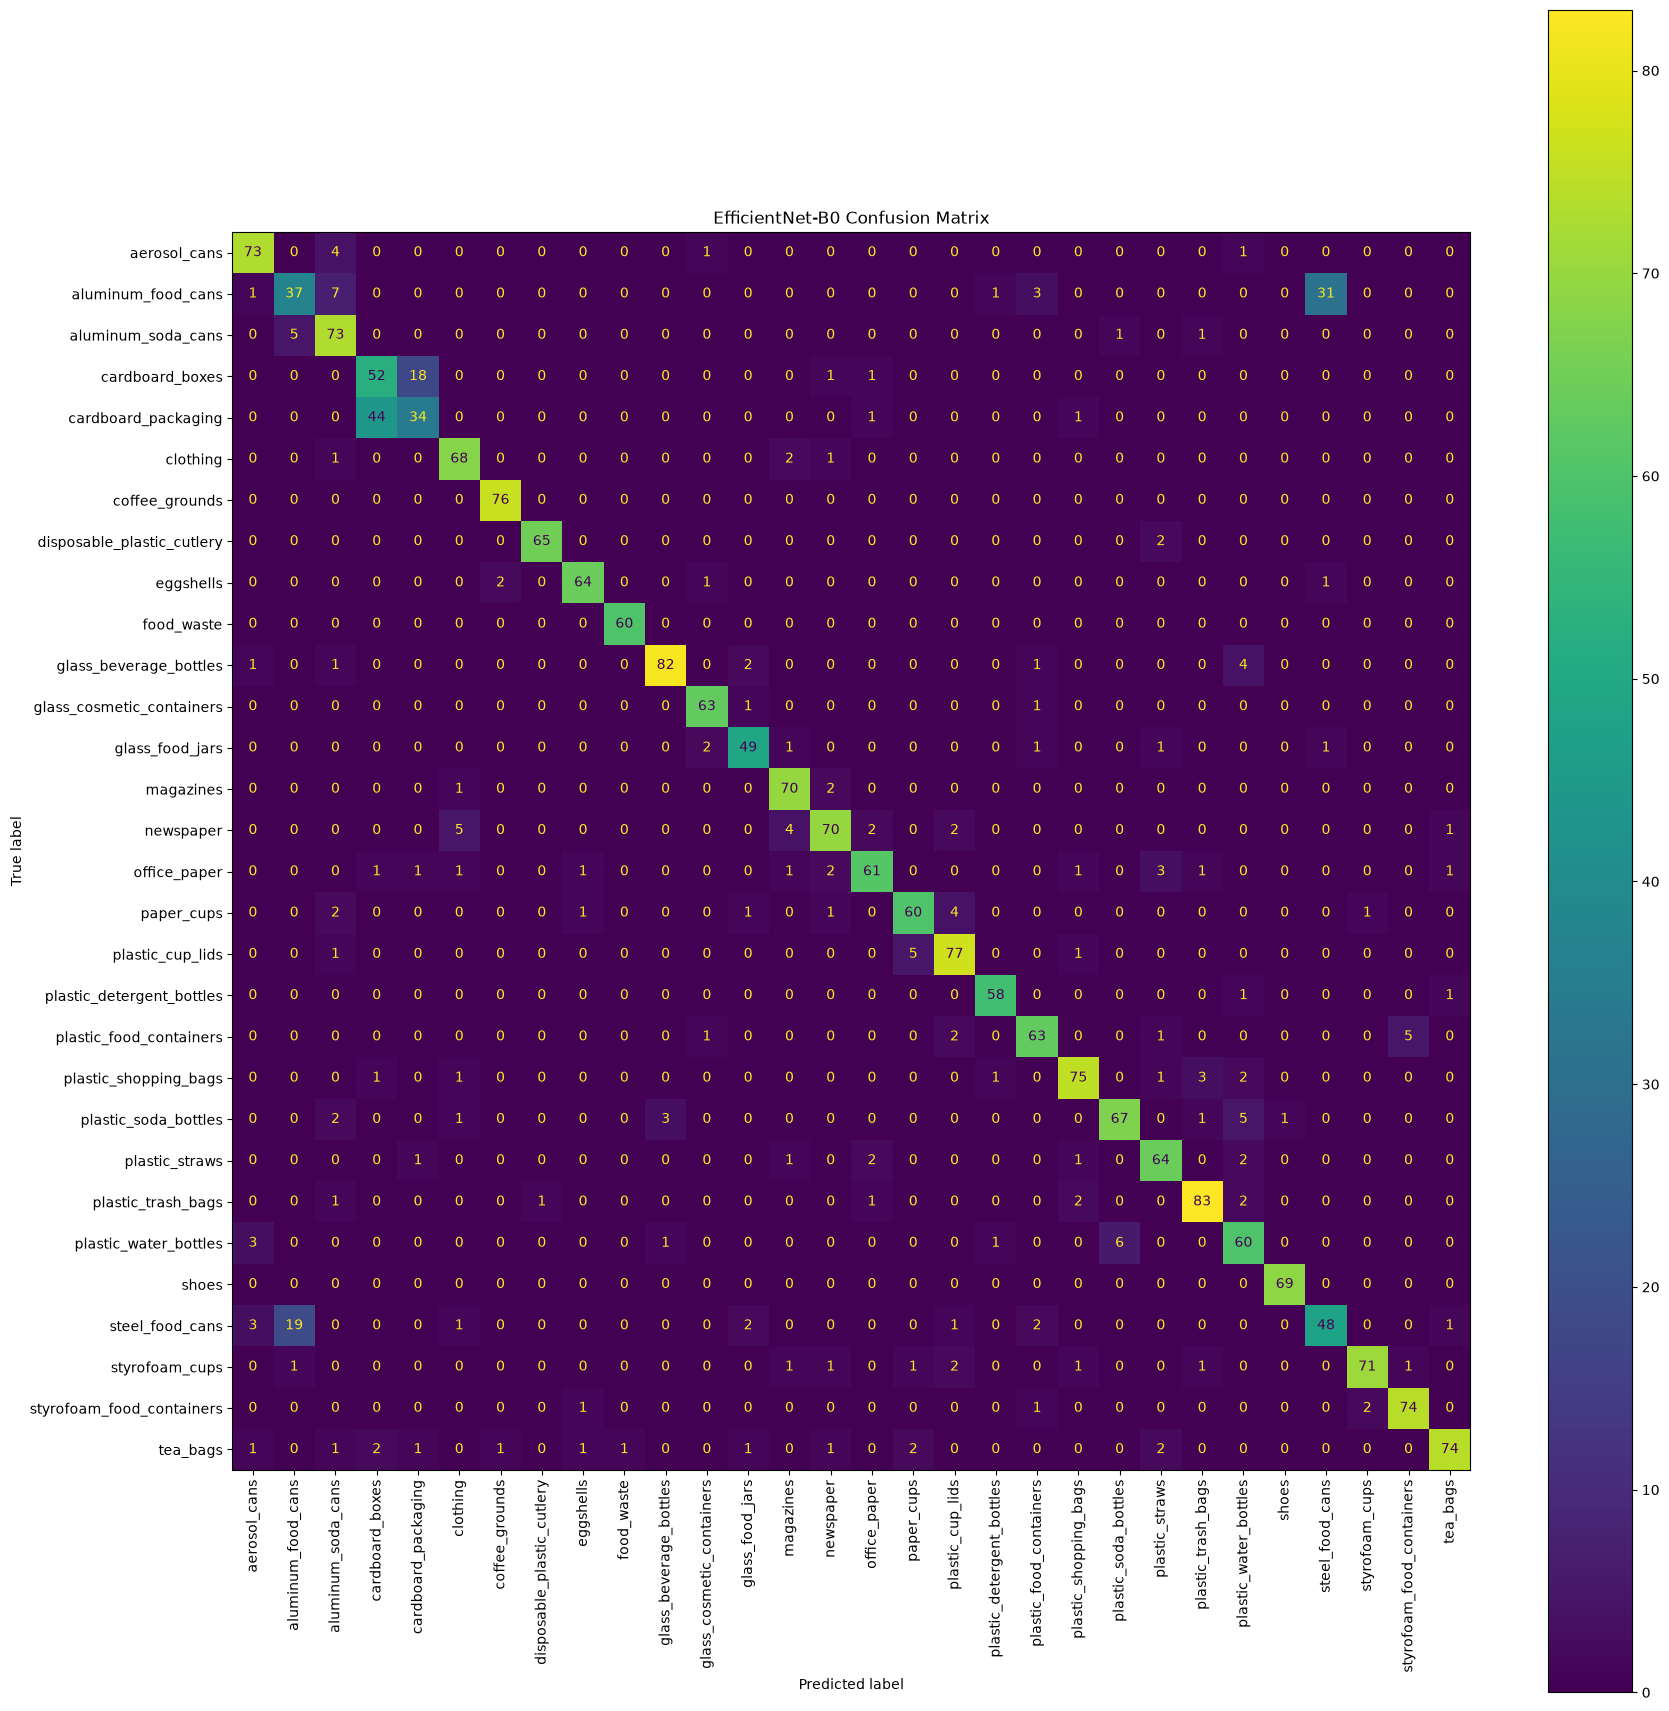

In [ ]:
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.classes
)

fig, ax = plt.subplots(figsize=(18, 18))
disp.plot(ax=ax, xticks_rotation=90)

plt.title("EfficientNet-B0 Confusion Matrix")
plt.tight_layout()

plt.savefig("../results/efficientb0_confusion_matrix.png")

plt.show()

In [ ]:
report = classification_report(
    all_labels,
    all_predictions,
    target_names=dataset.classes
)

with open("../results/efficientb0_classification_report.txt", "w") as f:
    f.write(report)

print("Classification report saved successfully!")

Classification report saved successfully!


In [14]:
print(class_names)

['aerosol_cans', 'aluminum_food_cans', 'aluminum_soda_cans', 'cardboard_boxes', 'cardboard_packaging', 'clothing', 'coffee_grounds', 'disposable_plastic_cutlery', 'eggshells', 'food_waste', 'glass_beverage_bottles', 'glass_cosmetic_containers', 'glass_food_jars', 'magazines', 'newspaper', 'office_paper', 'paper_cups', 'plastic_cup_lids', 'plastic_detergent_bottles', 'plastic_food_containers', 'plastic_shopping_bags', 'plastic_soda_bottles', 'plastic_straws', 'plastic_trash_bags', 'plastic_water_bottles', 'shoes', 'steel_food_cans', 'styrofoam_cups', 'styrofoam_food_containers', 'tea_bags']
